- <font size="3">The least squares method</font>
  - <font size="3">PDF of best-fit parameter(s)</font>
- <font size="3">MCMC</font>
  - <font size="3">Bayes rule</font>
  - <font size="3">likelihood, prior and posterior</font>

### Preamble

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

MEDIUM_SIZE = 16
BIGGER_SIZE = 18

plt.rcdefaults()

# plt.rc('font',**{'family':'serif','serif':['Times']})
# plt.rc('text', usetex=True)

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


%matplotlib inline

In [2]:
# a new library to install

import corner  # for drawing a corner-like grid of plots
from scipy.optimize import curve_fit

### A single-parameter line $y=kx$

#### Data

In [3]:
# our model for data (with one parameter k)

def f1(x,k):
    
    return k*x

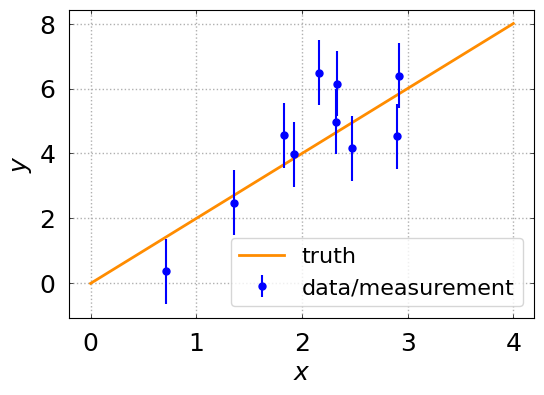

In [4]:
# generate data 

np.random.seed(13)   # a random seed to have the same data every time we run this code cell

k0 = 2  # a "true" value for k

n_pts = 10
sigma = 1   # sigma for a Gaussian noise

x_data = 3*np.random.random(n_pts)   # x values for the "measurement"
y_true = f1(x_data,k0)   # true y values
noise = sigma*np.random.randn(n_pts)
y_data = y_true + noise   # the data = true values + the noise
xx = np.linspace(0,4,500)
yy = f1(xx, k0)

# let us record the data for future use below

data_one_par = [x_data.copy(), y_data.copy(), k0, sigma]

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(xx,yy, c='darkorange', lw=2, label='truth')
ax.errorbar(x_data,y_data, yerr=sigma, fmt='b.', ms=10, label='data/measurement')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')

ax.legend()

### The method of least squares (LS)

If we have measurements $y_1, y_2, \ldots$ at points $x_1, x_2, \ldots$ as well as a model $y=f(x,\theta)$ with one or more parameters (the example is with a single parameter $\theta$), then in the LS method we are minimizing the deviations between the data and the model.

In the simplest version,

$$
\sum\limits_{i=1}^N\left[y_i - f(x_i,\theta)\right]^2 \to \mbox{min}
$$

If error bars $\sigma_1, \sigma_2, \ldots$ are given for each point, then

$$
\chi^2\equiv\sum\limits_{i=1}^N\frac{\left[y_i - f(x_i,\theta)\right]^2}{\sigma_i^2} \to \mbox{min}
$$

If all error bars are the same, then the second version reduces to the first again.

The scipy function `curve_fit` implements the LS method.

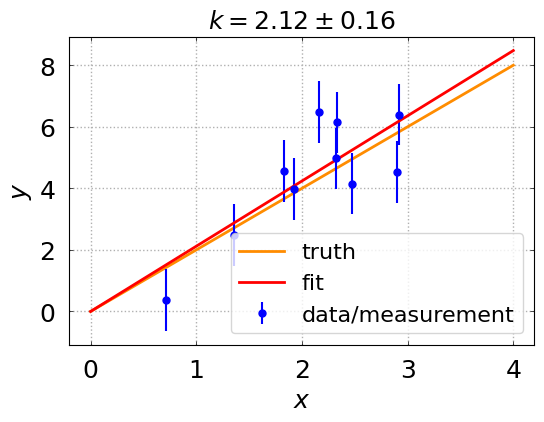

In [5]:
coefs,pcov = curve_fit(f1, x_data, y_data)   # pcov 

# sigmas = np.full_like(y_data, sigma)
# coefs,pcov = curve_fit(f, x_data, y_data, sigma=sigmas)
k = coefs[0]
dk = np.sqrt(np.diag(pcov))[0]
y_fit = f1(xx, k)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(xx,yy, c='darkorange', lw=2, label='truth')
ax.errorbar(x_data,y_data, yerr=sigma, fmt='b.', ms=10, label='data/measurement')
ax.plot(xx, y_fit, c='red', lw=2, label='fit')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')

ax.set_title('$k={:.2f}\pm{:.2f}$'.format(k, dk))

ax.legend();



<u>EXERCISE</u>

Experiment with the above:
1. increase/decrease the number of points; any changes to the best-fitting line and the error?
2. using the data from the example, make the sigma different for different points. For example, in an experiment large values of $x$ might have larger values, so that you can set $\sigma_i = \sigma x_i$ (the error is proportional to $x$). To make scipy use those errors, use the `sigma` keyword: `curve_fit(..., sigma=...)`.

#### Distribution of the best-fit parameters

Our data points are partially random. For example, different students doing similar measurements will get a bit different values for the best $k$ due to random noise. Let us look at how those best-fit values are distributed in our example.

In [6]:
# no random seed here, because we want the noise to be different each time

sample_size = 10000

k_samples = []

for i in range(sample_size):

    noise = sigma*np.random.randn(n_pts)
    y_data = y_true + noise
    coefs,_ = curve_fit(f1, x_data, y_data)
    k_samples.append(coefs[0])
    
k_samples = np.array(k_samples)
k_mean = np.mean(k_samples)
k_rms = np.std(k_samples)

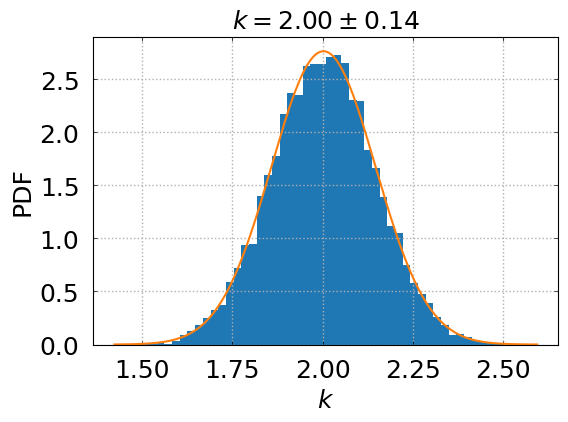

In [7]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.hist(k_samples, bins=50, density=True)

kmin,kmax = ax.get_xlim()
k_val = np.linspace(kmin, kmax, 500)
gauss_estimate = 1./np.sqrt(2*np.pi)/k_rms * np.exp(-(k_val-k_mean)**2/2/k_rms**2)
ax.plot(k_val, gauss_estimate)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_title('$k={:.2f}\pm{:.2f}$'.format(k_mean, k_rms))

ax.set_xlabel('$k$')
ax.set_ylabel('PDF');

### A two-parameter line $y=kx+b$

#### Data

In [8]:
# our model for data (with one parameter k)

def f2(x,k,b):
    
    return k*x + b

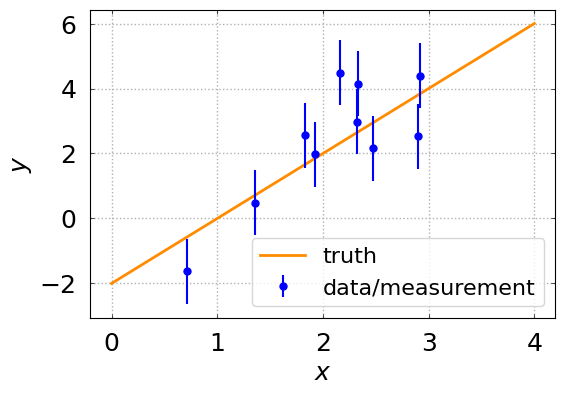

In [9]:
# generate data 

np.random.seed(13)   # a random seed to have the same data every time we run this code cell

k0 = 2  # a "true" value for k
b0 = -2

n_pts = 10
sigma = 1   # sigma for a Gaussian noise

x_data = 3*np.random.random(n_pts)   # x values for the "measurement"
y_true = f2(x_data,k0,b0)   # true y values
noise = sigma*np.random.randn(n_pts)
y_data = y_true + noise   # the data = true values + the noise
xx = np.linspace(0,4,500)
yy = f2(xx, k0, b0)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(xx,yy, c='darkorange', lw=2, label='truth')
ax.errorbar(x_data,y_data, yerr=sigma, fmt='b.', ms=10, label='data/measurement')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')

ax.legend()

<u>EXERCISE</u>

Complete the two-parameter case following the steps for the one-parameter one. That is,
1. Find the best-fit $k$ and $b$ for the new data and overplot the best-fit line.
2. Sampling the noise, obtain the distributions of $k$ and $b$.

*Hint*. With more than one parameter, the `pcov` output from `curve_fit` is an array. The parameters' errors can be obtained as `np.sqrt(np.diag(pcov))` (this will be a 1D array with a length equal to the number of parameters).

#### A 2D Gaussian PDF

The spread of a Gaussian in two dimensions $(x,y)$ is specified by the so-called *covariance matrix*:

$$
\Sigma = \left(
\begin{array}{cc}
\sigma_x^2 & \rho\sigma_x\sigma_y \\
\rho\sigma_x\sigma_y & \sigma_y^2
\end{array}
\right)\,,
$$

where $\sigma_x$, $\sigma_y$ are the r.m.s. deviations in $x$ and $y$, respectively, and $\rho$ is the so-called *correlation coefficient*, which is always $-1\leq\rho\leq 1$.

For the PDF, we then have

$$
\mbox{PDF}\propto \exp\left\{-\frac 12\mathbf{r}^{\rm T}\Sigma^{-1}\mathbf{r}\right\}\,,
$$
where $\mathbf{r}$ and $\mathbf{r}^{\rm T}$ are the column and row vectors of the coordinates:

$$
\mathbf{r} = \left(
\begin{array}{c}
x \\
y
\end{array}
\right) \qquad 
\mathbf{r}^{\rm T} = \left(
\begin{array}{cc}
x & y
\end{array}
\right)
$$

A numpy function that can generate samples from a 2D (or multi-D) Gaussian is `np.random.multivariate_normal(...)`

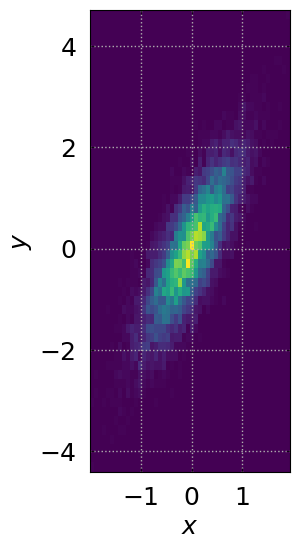

In [10]:

sigma_x = 0.5
sigma_y = 1.
rho=0.8

means = np.array([0.,0.])
cov = np.array([[sigma_x**2,rho*sigma_x*sigma_y],\
                 [rho*sigma_x*sigma_y, sigma_y**2]])

sample_size = 10000

gaussian_2D = np.random.multivariate_normal(means, cov, size=sample_size)

samples_x, samples_y = gaussian_2D.T

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,6))

ax.hist2d(samples_x, samples_y, bins=50, density=True)


ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_aspect('equal')

ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

<u>EXERCISE</u>

Experiment with the parameters of the 2D Gaussian. What changes when you change the correlation coefficient $\rho$? Describe in your own words what this coefficient is responsible for. 

#### Corner plots

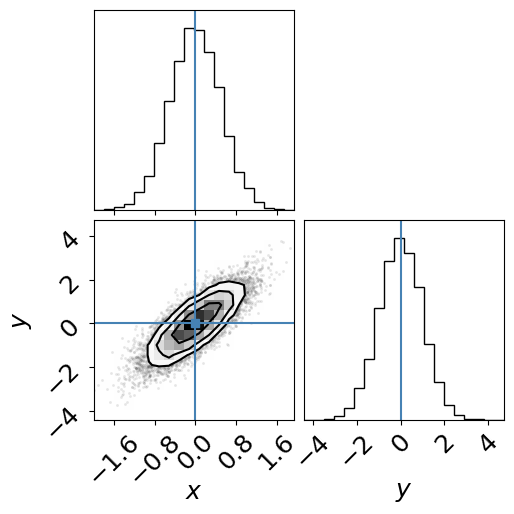

In [11]:
fig = corner.corner(
    gaussian_2D, labels=['$x$', '$y$'], truths=means
);

### MCMC

#### Bayes rule

We need three ingredients to use MCMC for data inference: 

1. *Likelihood* $p\left(D|\theta\right)$ (a.k.a. generative model). Given parameters $\theta$ (can be a vector of parameters), the likelihood function gives the probability to have specific data $D$ (can be a multidimensional array of data).
2. *Prior* $p(\theta)$. The prior is a PDF for the parameters $\theta$ *before* (i.e. prior to) taking the data into account. It can be a result of some previous experiment, for example. If there is no prior information on $\theta$, it is common to use flat priors (that is, $\theta$ is uniform in some range).
3. *Posterior* $p\left(\theta|D\right)$. The posterior gives a PDF for the parameters $\theta$ *after* (i.e. a posteriori) taking the data into account.

The Bayes rule gives a relation between these three:

$$
p\left(\theta|D\right) \propto p(\theta)p\left(D|\theta\right)\,.
$$

Then, MCMC can be used to sample from the posterior known the likelihood and the prior.


In [12]:
def log_likelihood(theta, x_data, y_data):
    
    k = theta
    return -0.5*np.sum((k*x_data - y_data)**2)

def log_prior(theta):
    
    k = theta
#     return -np.log(1+k**2)
    if 0.5<k<4:   # flat prior
        return 0.
    return -np.inf

def log_prob(theta, x_data, y_data):
    
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x_data, y_data)
    

In [22]:
sigma = 1.
sample_size = 10000

xd, yd, k0, _ = data_one_par

k_old = 1.
samples = [k_old]

for i in range(sample_size):
    k_new = sigma*np.random.randn() + k_old
    r = np.random.random()
    

    if log_prob(k_new, xd, yd)-log_prob(k_old, xd, yd) > np.log(r):
        k_old = k_new

    samples.append(k_old)
    
samples = np.array(samples)

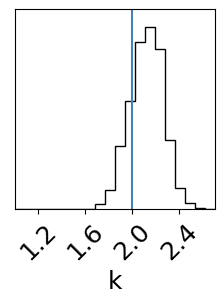

In [28]:
labels = ['k']
truths = [k0]

fig = corner.corner(
    samples, labels=labels, truths=truths
);

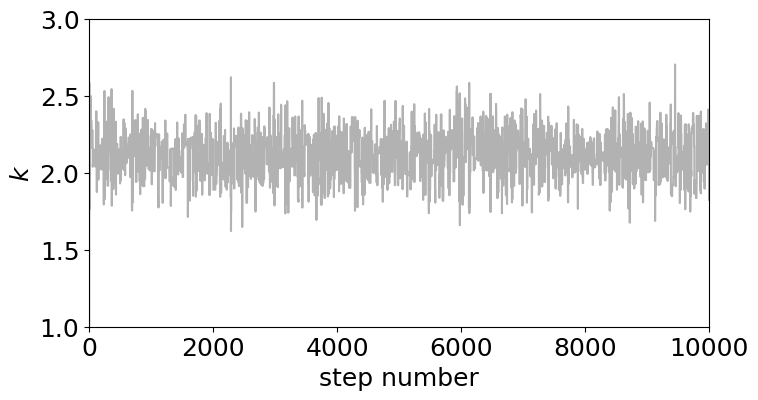

In [30]:
fig, ax = plt.subplots(1, figsize=(8, 4), sharex=True)


ax.plot(samples, "k", alpha=0.3)
ax.set_xlim(0, len(samples))
ax.set_ylim(1, 3)
ax.set_ylabel('${}$'.format(labels[0]))
#ax.yaxis.set_label_coords(-0.1, 0.5)

ax.set_xlabel("step number");

In [ ]:
flat_samples = sampler.get_chain(discard=1000, thin=15, flat=True)
print(flat_samples.shape)

fig = corner.corner(
    flat_samples, labels=labels, truths=[k0]
);

In [ ]:
from IPython.display import display, Math

for i in range(ndim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)
    txt = "\mathrm{{{3}}} = {0:.3f}_{{-{1:.3f}}}^{{{2:.3f}}}"
    txt = txt.format(mcmc[1], q[0], q[1], labels[i])
    display(Math(txt))

In [ ]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.hist(flat_samples, bins=50, density=True)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$k$')
ax.set_ylabel('PDF')

In [ ]:
1/np.sqrt(np.sum(x**2))

In [ ]:
np.sqrt(np.mean(flat_samples**2) - np.mean(flat_samples)**2)

In [ ]:
np.std(k_samples)